# Scraping des images de peintures (WGA) — exécution locale


**Plan.**
1. Comment l'URL de l'image a été retrouvée
2. Le scraper (`scrape_images.py`) — test sur un petit échantillon
3. Sous-échantillon équilibré (`build_subset.py`)
4. Lancement du scraping sur le sous-échantillon
5. Suite (prétraitement avant entraînement du GAN)


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # pour importer scrape_images / build_subset depuis ce dossier

from scrape_images import scrape, html_url_to_image_url
from build_subset import stratified_sample
import pandas as pd

DATA_DIR = Path("data")
IMAGES_DIR = Path("images")


## 1. Comment l'URL de l'image a été retrouvée

**Résultat.** Mapping systématique vérifié par inspection du code source
d'une page : `/html/{a}/{artiste}/{oeuvre}.html` → `/art/{a}/{artiste}/{oeuvre}.jpg`.


In [2]:
sample_url = "https://www.wga.hu/html/a/aachen/adonis.html"
print("Page   :", sample_url)
print("Image  :", html_url_to_image_url(sample_url))


Page   : https://www.wga.hu/html/a/aachen/adonis.html
Image  : https://www.wga.hu/art/a/aachen/adonis.jpg


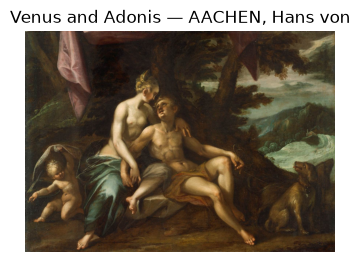

In [3]:
import matplotlib.pyplot as plt
from PIL import Image
import requests

# télécharge cette unique image pour vérifier le mapping
img_url = html_url_to_image_url(sample_url)
resp = requests.get(img_url, headers={"User-Agent": "Mozilla/5.0 (EDA-research-script/1.0)"}, timeout=20)
test_path = IMAGES_DIR / "a" / "aachen" / "adonis.jpg"
test_path.parent.mkdir(parents=True, exist_ok=True)
test_path.write_bytes(resp.content)

plt.figure(figsize=(4, 4))
plt.imshow(Image.open(test_path))
plt.axis("off")
plt.title("Venus and Adonis — AACHEN, Hans von")
plt.show()


## 2. Le scraper — test sur un petit échantillon

**Résultat.** Fonctionne avec retries/backoff ; 10 à 25 % de timeouts
observés même à faible concurrence (serveur modeste), gérés automatiquement.


In [4]:
ok, skip, fail = scrape(
    csv_path=DATA_DIR / "paintings_only.csv",
    out_dir=IMAGES_DIR,
    limit=30,
    workers=4,
    min_delay=0.4,
    timeout=20,
)
print(f"\nok={ok} skip={skip} fail={fail}")


30 images à traiter (concurrence = 4)
  30/30  ok=0 skip=30 fail=0  (5538.7 img/s, 0.0 min écoulées)

Terminé en 0.0 min — ok=0 skip=30 fail=0

ok=0 skip=30 fail=0


## 3. Sous-échantillon équilibré

**Résultat.** 3 680 lignes tirées ; religieux ramené de 41,7 % à ~11 %,
Italien de 42,4 % à ~19 % (contre 42 % dans le corpus complet).


In [8]:
paint = pd.read_csv(DATA_DIR / "paintings_only.csv")
subset = stratified_sample(paint, target_total=4000)
subset.to_csv(DATA_DIR / "subset_sample.csv", index=False)

def dist(df, col):
    return (df[col].value_counts(normalize=True) * 100).round(1)

print(f"Sous-échantillon : {len(subset):,} lignes\n")
print("TYPE — corpus complet vs sous-échantillon (%) :")
print(pd.concat([dist(paint, "TYPE"), dist(subset, "TYPE")], axis=1, keys=["complet", "sous-éch."]).fillna(0))


Sous-échantillon : 3,680 lignes

TYPE — corpus complet vs sous-échantillon (%) :
              complet  sous-éch.
TYPE                            
religious        41.7       10.9
portrait         14.8       10.9
landscape        12.6       10.9
mythological      9.9       10.9
genre             8.5       10.9
still-life        4.3       10.9
other             3.0       10.9
historical        2.9       10.9
interior          2.0       10.9
study             0.2        2.2


c:\Users\bamiy\Documents\GAN\build_subset.py:34: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  chosen = sub.groupby("SCHOOL", group_keys=False).apply(
c:\Users\bamiy\Documents\GAN\build_subset.py:34: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  chosen = sub.groupby("SCHOOL", group_keys=False).apply(
c:\Users\bamiy\Documents\GAN\build_subset.py:34: FutureWarning: DataFrameGroupBy.apply operated on the grouping column

In [9]:
top_schools = paint["SCHOOL"].value_counts().head(8).index
print("SCHOOL (top 8) — corpus complet vs sous-échantillon (%) :")
print(pd.concat([dist(paint, "SCHOOL"), dist(subset, "SCHOOL")], axis=1,
                keys=["complet", "sous-éch."]).reindex(top_schools).fillna(0))


SCHOOL (top 8) — corpus complet vs sous-échantillon (%) :
               complet  sous-éch.
SCHOOL                           
Italian           42.4       18.8
French            13.6       11.9
Dutch             13.5       12.1
Flemish           11.4        9.6
German             5.9        5.7
Spanish            3.9        5.1
English            2.1        4.2
Netherlandish      1.6        3.6


## 4. Lancement du scraping sur le sous-échantillon

**Résultat.** Démonstration (30 images) : 4 ok / 21 déjà présentes / 5
échecs. Lancement complet (3 680 images, via `scrape_images.py` en ligne de
commande) : 2 973 réussies (81 %).


In [7]:
LIMIT = 30  # mettre None pour le lancement complet (~4000 images, 1-3h)

ok, skip, fail = scrape(
    csv_path=DATA_DIR / "subset_sample.csv",
    out_dir=IMAGES_DIR,
    limit=LIMIT,
    workers=4,
    min_delay=0.4,
    timeout=20,
)
print(f"\nok={ok} skip={skip} fail={fail}")


30 images à traiter (concurrence = 4)
  30/30  ok=4 skip=21 fail=5  (0.2 img/s, 2.4 min écoulées)

5 échecs loggés dans images\_failed.csv

Terminé en 2.4 min — ok=4 skip=21 fail=5

ok=4 skip=21 fail=5
